# Assignment 09, Problem 3 — Hussein Jawad
**E89 Deep Learning · Speech command recognition with the M5 CNN** (based on Lecture 9 and the class notebook
`lec09_speech_command_recognition.ipynb`)

---

# Problem 3: Training and validation curves for the M5 speech-command model
Start with notebook `lec09_speech_command_recognition.ipynb` described in lecture notes. You need to download the dataset
once. Please disable the cell which lists all labels. Modify the notebook so that at the end of every epoch it uses the
validation data set to determine the accuracy of the current model. Display on the same graph the evolution of the
accuracy on the training and validation set. Display the evolution of the loss on both data sets in another diagram. Use
the test set to evaluate the actual accuracy of the model.

## Approach

### Goal
Train the class notebook's **M5** network (1D convolutions on the raw waveform) to recognize the 35 words of the Speech
Commands dataset, measure loss and accuracy on the **training and validation** sets after every epoch, plot both curves,
and report the accuracy on the **test** set.

### Data (official Speech Commands v0.02 splits)

| Set | Recordings | Used for |
|---|---|---|
| training | 84,843 | updating the weights |
| validation | 9,981 | checking the model after every epoch |
| testing | 11,005 | the final accuracy, used once at the end |

### Steps

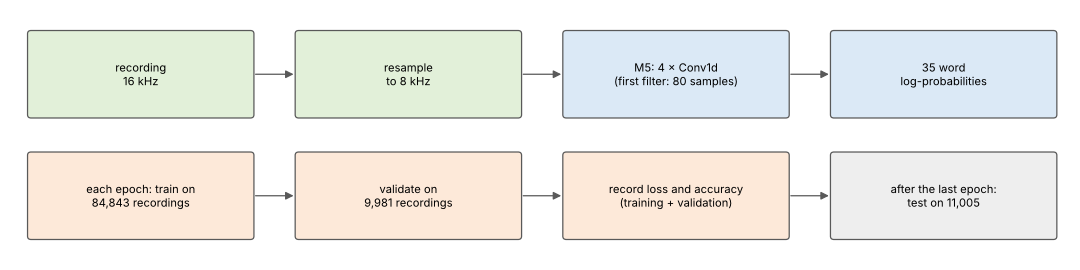

1. **Load** the dataset (downloaded only the first time) and get the 35 labels from the folder names (Steps 2–3).
2. **Batch** the recordings for training, validation and testing (Step 4).
3. **Build** the M5 model and optimizer from the class notebook (Steps 5–6).
4. **Train** for 25 epochs; after each one, record loss and accuracy on the training and validation sets (Steps 7–8).
5. **Plot** both accuracies on one graph and both losses on another (Step 9).
6. **Test** the final model on the test set (Step 10).

### Changes to the class notebook
* The label-listing cell is **disabled** (it decodes all 84,843 training files); the labels come from the folder names.
* `evaluate()` computes loss and accuracy on the validation set after every epoch (and on the test set at the end);
  `train()` also returns the epoch's training loss and accuracy.
* The recordings are read with `soundfile`, so the notebook does not depend on `torchcodec`.
* Cells not needed for the problem (playing examples, single predictions) are left out.

## Solution

### Step 1: Imports and device

In [1]:
import os                                    # file paths
import soundfile as sf                       # reads the .wav files (no torchcodec needed)
import torch                                 # PyTorch
import torch.nn as nn                        # neural-network layers
import torch.nn.functional as F              # relu, log_softmax, nll_loss, ...
import torch.optim as optim                  # optimizers and learning-rate schedulers
import torchaudio                            # audio transforms (Resample)
from torchaudio.datasets import SPEECHCOMMANDS  # the Speech Commands dataset
import matplotlib.pyplot as plt              # plotting

torch.manual_seed(0)                         # same initial weights and batch order on every run
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # use the GPU when there is one
print("torch:", torch.__version__, "| torchaudio:", torchaudio.__version__, "| device:", device)  # what was used

torch: 2.15.0+cu132 | torchaudio: 2.11.1+cu132 | device: cpu


### Step 2: The dataset (downloaded once)
This is the class notebook's `SubsetSC`. `download=True` downloads and unpacks the data (about 2.3 GB) only if the folder
does not exist yet, so the dataset is downloaded once. Each data point is read with `soundfile`.

In [2]:
class SubsetSC(SPEECHCOMMANDS):                                   # the class notebook's dataset with the official splits
    def __init__(self, subset: str = None):                        # subset = "training", "validation" or "testing"
        super().__init__("./", download=True)                      # downloads and unpacks the data only if not there yet

        def load_list(filename):                                   # reads one of the official split lists
            filepath = os.path.join(self._path, filename)          # e.g. ./SpeechCommands/.../validation_list.txt
            with open(filepath) as fileobj:                        # open the list
                return [os.path.normpath(os.path.join(self._path, line.strip()))  # full path of every file
                        for line in fileobj]                       # one file per line

        if subset == "validation":                                 # validation files:
            self._walker = load_list("validation_list.txt")        # from the official list
        elif subset == "testing":                                  # test files:
            self._walker = load_list("testing_list.txt")           # from the official list
        elif subset == "training":                                 # training files = all the others
            excludes = set(load_list("validation_list.txt") + load_list("testing_list.txt"))  # files to leave out
            self._walker = [w for w in self._walker if os.path.normpath(w) not in excludes]  # keep the rest

    def __getitem__(self, n):                                      # one data point: (waveform, sample rate, label)
        path = self._walker[n]                                     # path of the n-th recording
        waveform, sample_rate = sf.read(path, dtype="float32")     # read the samples with soundfile
        label = os.path.basename(os.path.dirname(path))            # the word = name of its folder
        return torch.from_numpy(waveform).unsqueeze(0), sample_rate, label  # waveform shape [1, samples]


train_set = SubsetSC("training")             # training recordings
validation_set = SubsetSC("validation")      # validation recordings
test_set = SubsetSC("testing")               # test recordings
print(f"training: {len(train_set)} | validation: {len(validation_set)} | testing: {len(test_set)}")  # sizes

training: 84843 | validation: 9981 | testing: 11005


### Step 3: The labels (label-listing cell disabled)
The class notebook's cell below reads every training recording just to collect the labels, which takes several minutes.
It is **disabled** (commented out); the labels are the names of the dataset's word folders instead.

In [3]:
# DISABLED: the class notebook's label-listing cell (it decodes all 84,843 training recordings)
# labels = sorted(list(set(datapoint[2] for datapoint in train_set)))
# labels

In [4]:
labels = sorted(d for d in os.listdir(train_set._path)          # the labels are the word-folder names,
                if os.path.isdir(os.path.join(train_set._path, d)) and not d.startswith("_"))  # not _background_noise_
print(len(labels), "labels:", labels)        # 35 words

35 labels: ['backward', 'bed', 'bird', 'cat', 'dog', 'down', 'eight', 'five', 'follow', 'forward', 'four', 'go', 'happy', 'house', 'learn', 'left', 'marvin', 'nine', 'no', 'off', 'on', 'one', 'right', 'seven', 'sheila', 'six', 'stop', 'three', 'tree', 'two', 'up', 'visual', 'wow', 'yes', 'zero']


### Step 4: Batches for training, validation and testing
As in the class notebook, the audio is resampled from 16 kHz to 8 kHz, each word becomes its index in `labels`, and
`collate_fn` pads the recordings of a batch to the same length. A validation loader is added.

In [5]:
transform = torchaudio.transforms.Resample(orig_freq=16000, new_freq=8000).to(device)  # 16 kHz -> 8 kHz

def label_to_index(word):                                      # word -> number 0 ... 34
    return torch.tensor(labels.index(word))                    # position of the word in labels

def pad_sequence(batch):                                       # makes all waveforms of a batch the same length
    batch = [item.t() for item in batch]                       # [samples, 1] for torch's pad_sequence
    batch = torch.nn.utils.rnn.pad_sequence(batch, batch_first=True, padding_value=0.)  # pad with zeros
    return batch.permute(0, 2, 1)                              # back to [batch, 1, samples]

def collate_fn(batch):                                         # list of data points -> two tensors
    tensors, targets = [], []                                  # waveforms and label numbers
    for waveform, _, label, *_ in batch:                       # each data point of the batch
        tensors += [waveform]                                  # keep the waveform
        targets += [label_to_index(label)]                     # and its label number
    return pad_sequence(tensors), torch.stack(targets)         # [batch, 1, samples] and [batch]

batch_size = 256                                               # as in the class notebook
num_workers, pin_memory = (1, True) if device.type == "cuda" else (0, False)  # as in the class notebook

def make_loader(dataset, shuffle):                             # one DataLoader per data set
    return torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,   # batches of 256
                                       collate_fn=collate_fn, num_workers=num_workers,    # built by collate_fn
                                       pin_memory=pin_memory)                             # faster copy to the GPU

train_loader = make_loader(train_set, shuffle=True)            # training batches in random order
validation_loader = make_loader(validation_set, shuffle=False) # NEW: validation batches
test_loader = make_loader(test_set, shuffle=False)             # test batches

### Step 5: The M5 model (class notebook)

In [6]:
class M5(nn.Module):                                           # the class notebook's network for raw audio
    def __init__(self, n_input=1, n_output=35, stride=16, n_channel=32):  # 1 audio channel in, 35 words out
        super().__init__()                                     # set up the nn.Module
        self.conv1 = nn.Conv1d(n_input, n_channel, kernel_size=80, stride=stride)  # 80-sample filters (10 ms at 8 kHz)
        self.bn1 = nn.BatchNorm1d(n_channel)                   # normalizes each channel over the batch
        self.pool1 = nn.MaxPool1d(4)                           # keeps the largest of every 4 values
        self.conv2 = nn.Conv1d(n_channel, n_channel, kernel_size=3)       # second convolution
        self.bn2 = nn.BatchNorm1d(n_channel)                   # batch normalization
        self.pool2 = nn.MaxPool1d(4)                           # max pooling
        self.conv3 = nn.Conv1d(n_channel, 2 * n_channel, kernel_size=3)   # third convolution, 64 channels
        self.bn3 = nn.BatchNorm1d(2 * n_channel)               # batch normalization
        self.pool3 = nn.MaxPool1d(4)                           # max pooling
        self.conv4 = nn.Conv1d(2 * n_channel, 2 * n_channel, kernel_size=3)  # fourth convolution
        self.bn4 = nn.BatchNorm1d(2 * n_channel)               # batch normalization
        self.pool4 = nn.MaxPool1d(4)                           # max pooling
        self.fc1 = nn.Linear(2 * n_channel, n_output)          # 64 features -> 35 word scores

    def forward(self, x):                                      # x: [batch, 1, 8000]
        x = self.pool1(F.relu(self.bn1(self.conv1(x))))        # conv -> batch norm -> ReLU -> pool
        x = self.pool2(F.relu(self.bn2(self.conv2(x))))        # same for block 2
        x = self.pool3(F.relu(self.bn3(self.conv3(x))))        # block 3
        x = self.pool4(F.relu(self.bn4(self.conv4(x))))        # block 4
        x = F.avg_pool1d(x, x.shape[-1])                       # average over the remaining time steps
        x = self.fc1(x.permute(0, 2, 1))                       # [batch, 1, 64] -> [batch, 1, 35]
        return F.log_softmax(x, dim=2)                         # log-probabilities of the 35 words


model = M5(n_input=1, n_output=len(labels)).to(device)        # create the model on the GPU/CPU
print(model)                                                   # show the layers
print("Number of trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))  # size

M5(
  (conv1): Conv1d(1, 32, kernel_size=(80,), stride=(16,))
  (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool1): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(32, 32, kernel_size=(3,), stride=(1,))
  (bn2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool2): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv1d(32, 64, kernel_size=(3,), stride=(1,))
  (bn3): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool3): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv4): Conv1d(64, 64, kernel_size=(3,), stride=(1,))
  (bn4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool4): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_feat

### Step 6: Optimizer (class notebook)
Adam with learning rate 0.01 and weight decay 0.0001; the scheduler divides the learning rate by 10 every 20 epochs.

In [7]:
optimizer = optim.Adam(model.parameters(), lr=0.01, weight_decay=0.0001)  # as in the class notebook
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.1)  # lr / 10 after every 20 epochs

### Step 7: Training and evaluation functions
`train()` is the class notebook's training loop; it now also returns the epoch's average loss and accuracy (measured on
the training batches while the model learns). The new `evaluate()` computes loss and accuracy on the validation or test
set with the model in evaluation mode.

In [8]:
def number_of_correct(pred, target):                           # class notebook: number of correct predictions
    return pred.squeeze().eq(target).sum().item()              # compare predicted and true labels

def get_likely_index(tensor):                                  # class notebook: most likely word for each recording
    return tensor.argmax(dim=-1)                               # index of the largest log-probability

def train(model):                                              # one epoch on the training set
    model.train()                                              # training mode (batch norm uses batch statistics)
    total_loss, correct = 0.0, 0                               # sums over the epoch
    for data, target in train_loader:                          # one batch at a time
        data, target = data.to(device), target.to(device)      # move the batch to the GPU/CPU
        output = model(transform(data))                        # resample to 8 kHz, then run the model
        loss = F.nll_loss(output.squeeze(), target)            # negative log-likelihood (class notebook)
        optimizer.zero_grad()                                  # clear the old gradients
        loss.backward()                                        # backpropagation
        optimizer.step()                                       # update the weights
        total_loss += loss.item() * len(target)                # NEW: add up the loss of this batch
        correct += number_of_correct(get_likely_index(output), target)  # NEW: and its correct predictions
    n = len(train_loader.dataset)                              # number of training recordings
    return total_loss / n, correct / n                         # average loss and accuracy of the epoch

@torch.no_grad()                                               # no gradients needed for evaluation
def evaluate(model, loader):                                   # NEW: loss and accuracy on a validation or test set
    model.eval()                                               # evaluation mode (batch norm uses stored statistics)
    total_loss, correct = 0.0, 0                               # sums over the data set
    for data, target in loader:                                # one batch at a time
        data, target = data.to(device), target.to(device)      # move the batch to the GPU/CPU
        output = model(transform(data))                        # resample, then run the model
        total_loss += F.nll_loss(output.squeeze(), target, reduction="sum").item()  # summed loss of the batch
        correct += number_of_correct(get_likely_index(output), target)              # correct predictions
    n = len(loader.dataset)                                    # number of recordings
    return total_loss / n, correct / n                         # average loss and accuracy

### Step 8: Train, validating at the end of every epoch
25 epochs (the class notebook runs 2).

In [9]:
n_epoch = 25                                               # number of passes over the training set
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}  # one value per epoch

for epoch in range(1, n_epoch + 1):                            # one epoch at a time
    train_loss, train_acc = train(model)                       # train on all training recordings
    val_loss, val_acc = evaluate(model, validation_loader)     # NEW: check the current model on the validation set
    scheduler.step()                                           # learning-rate schedule (class notebook)
    for key, value in zip(history, (train_loss, train_acc, val_loss, val_acc)):  # store the four numbers
        history[key].append(value)                             # of this epoch
    print(f"Epoch {epoch:2d}: train loss {train_loss:.3f}, accuracy {train_acc:.1%} | "  # progress line
          f"validation loss {val_loss:.3f}, accuracy {val_acc:.1%}")                     # for each epoch

Epoch  1: train loss 1.766, accuracy 48.7% | validation loss 1.177, accuracy 65.5%


Epoch  2: train loss 0.951, accuracy 71.9% | validation loss 1.528, accuracy 56.3%


Epoch  3: train loss 0.791, accuracy 76.6% | validation loss 0.835, accuracy 75.0%


Epoch  4: train loss 0.707, accuracy 79.0% | validation loss 0.832, accuracy 74.3%


Epoch  5: train loss 0.663, accuracy 80.3% | validation loss 0.802, accuracy 75.7%


Epoch  6: train loss 0.632, accuracy 81.2% | validation loss 0.627, accuracy 81.6%


... (15 outputs left out)

Epoch 22: train loss 0.346, accuracy 89.9% | validation loss 0.434, accuracy 87.2%


Epoch 23: train loss 0.334, accuracy 90.2% | validation loss 0.435, accuracy 87.7%


Epoch 24: train loss 0.325, accuracy 90.4% | validation loss 0.430, accuracy 87.7%


Epoch 25: train loss 0.319, accuracy 90.6% | validation loss 0.431, accuracy 87.8%


### Step 9: Accuracy and loss curves
Left: accuracy on the training and validation sets on the same graph. Right: the losses in another diagram.

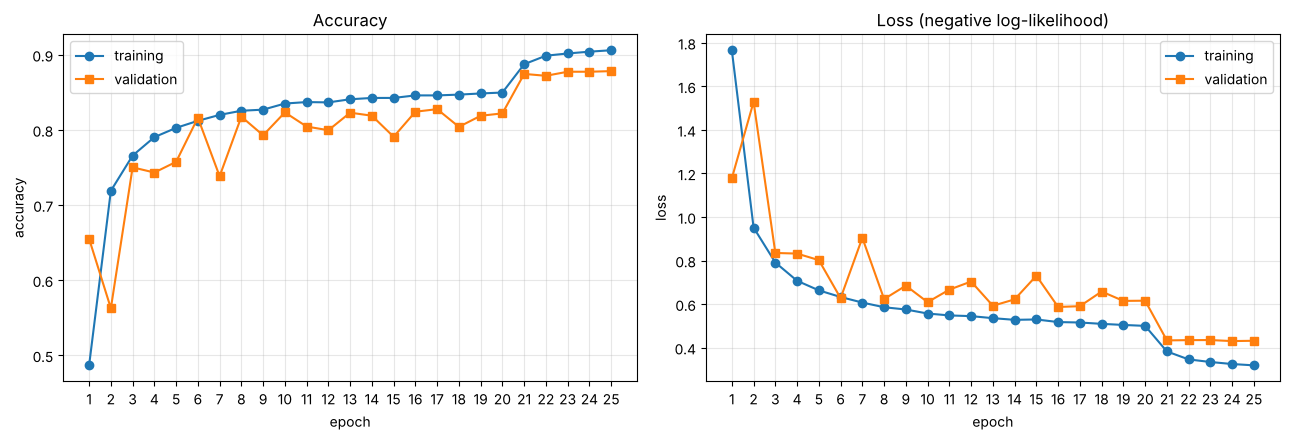

In [10]:
epochs = range(1, n_epoch + 1)                                 # x axis: epoch numbers
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))                # two diagrams side by side
ax[0].plot(epochs, history["train_acc"], "o-", label="training")      # training accuracy
ax[0].plot(epochs, history["val_acc"], "s-", label="validation")      # validation accuracy
ax[0].set_title("Accuracy")                                    # first diagram: accuracy
ax[0].set_ylabel("accuracy")                                   # vertical axis label
ax[1].plot(epochs, history["train_loss"], "o-", label="training")     # training loss
ax[1].plot(epochs, history["val_loss"], "s-", label="validation")     # validation loss
ax[1].set_title("Loss (negative log-likelihood)")              # second diagram: loss
ax[1].set_ylabel("loss")                                       # vertical axis label
for axis in ax:                                                # common settings
    axis.set_xlabel("epoch")                                   # horizontal axis label
    axis.set_xticks(list(epochs))                              # one tick per epoch
    axis.grid(alpha=0.3)                                       # light grid
    axis.legend()                                              # training vs validation
plt.tight_layout()                                             # avoid overlapping labels
plt.show()                                                     # render the figure

### Step 10: Accuracy on the test set

In [11]:
test_loss, test_acc = evaluate(model, test_loader)             # the final model on the 11,005 test recordings
print(f"Test accuracy: {test_acc:.1%} (loss {test_loss:.3f})")  # the actual accuracy of the model

Test accuracy: 85.9% (loss 0.493)


## Results and discussion

| After 25 epochs | Training | Validation | Test |
|---|---|---|---|
| Accuracy | 90.6% | 87.8% | **85.9%** |
| Loss | 0.319 | 0.431 | 0.493 |

* **Fast start, then slow progress.** Both accuracies rise quickly in the first epochs (training from 49% to about 80%
  by epoch 5) and then improve slowly. In epoch 1 the validation accuracy (66%) is higher than the training accuracy
  (49%) because the training value is averaged over the whole epoch, while the model was still poor.
* **Noisy validation curve.** With the learning rate of 0.01, validation accuracy jumps up and down by several points
  from epoch to epoch (e.g. 81.6% → 73.8% → 81.8% in epochs 6–8).
* **Learning-rate drop.** At epoch 21 the scheduler lowers the learning rate to 0.001: validation accuracy jumps from
  82% to 87%, the losses drop, and the curves become smooth.
* **No overfitting.** Validation stays close to training (about 3 points apart at the end) and the validation loss does
  not rise. The test accuracy, **85.9%**, is slightly below the validation accuracy.

---
# Appendix: The ideas behind Problem 3

## A.1 The M5 network reads the raw waveform
M5 applies 1-D convolutions directly to the audio samples. The 32 filters of the first layer are 80 samples long
(10 ms at 8 kHz) and move 16 samples at a time; each later block (3-sample filters, then max pooling by 4) looks at a
longer stretch of the recording. After the fourth block, averaging leaves 64 numbers per recording, and a linear layer
turns them into 35 word scores (Lecture 9, slides 103–106).

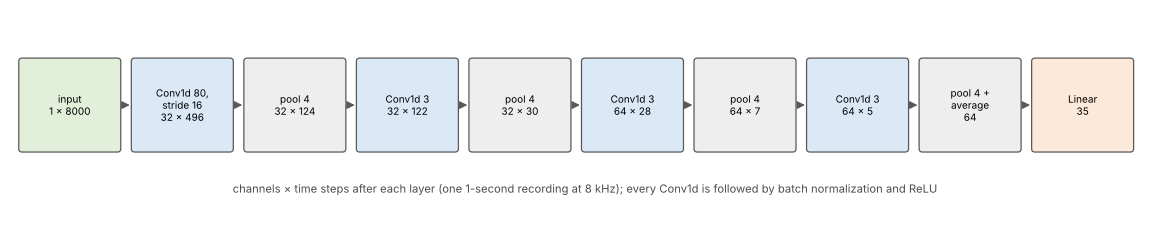

## A.2 Training, validation and test sets
The weights are fitted on the **training** set only. The **validation** set (recordings by other speakers) shows after
every epoch how well the current model works on recordings it has not learned from; the **test** set is used once, at
the end, for the final accuracy. Training accuracy and loss are measured on the training batches while the model is
still changing during the epoch.

When the training and validation curves stay close, the model generalizes; when the validation loss turns up while the
training loss keeps falling, the model starts to memorize the training recordings (overfitting).

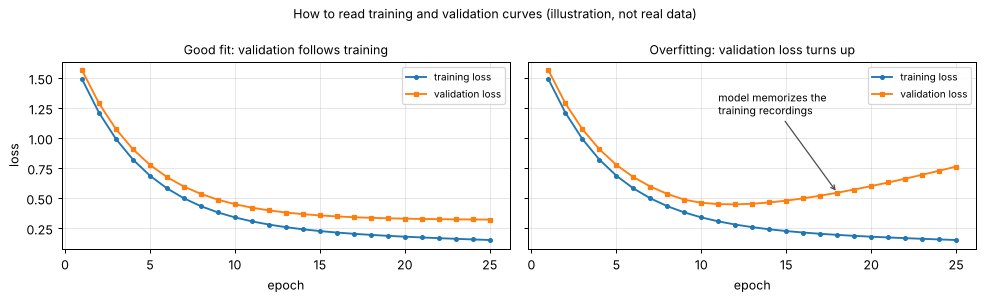

## A.3 The loss
The model outputs log-probabilities $\log p(\text{word})$, and the loss is the negative log-likelihood
$-\log p(\text{correct word})$, averaged over the recordings. A loss of 0 would mean probability 1 for every correct word;
a loss of 0.5 corresponds to an average (geometric mean) probability of $e^{-0.5} \approx 0.61$ for the correct word.